# Finite-Time Lyapunov Exponents (FTLEs)

For a $D$-dimensional dynamical system, the Lyapunov spectrum consists of $D$ exponents that quantify the average exponential rates at which nearby trajectories diverge or converge in phase space. The largest Lyapunov exponent measures the average exponential divergence of infinitesimally close trajectories,

$$
\lambda_m = \lim_{t \to \infty} \frac{1}{t}\ln\frac{d(t)}{d(0)},
$$

where $d(0)$ is the initial separation and $d(t)$ is the separation after time $t$. Since this is defined in the limit $t \rightarrow \infty$, it provides an asymptotic measure of stability.

To capture local stability over finite time intervals, **Finite-Time Lyapunov Exponents (FTLEs)** are computed. The trajectory is divided into segments of length $N$, and the FTLE for the $k^{\mathrm{th}}$ segment is

$$
\lambda_N(k)=\frac{1}{N}\sum_{j=N(k-1)+1}^{kN}\lambda_1(j),
$$

where $\lambda_1(j)$ is the single-step Lyapunov exponent.

## FTLE Computation

1. Simulate a reference trajectory together with an infinitesimally perturbed trajectory.
2. Compute the single-step stretching rate at each iteration.
3. Average these values over a window of length $N$ to obtain the $N$-step FTLE.
4. Shift the window by one time step and repeat, generating an ensemble of overlapping FTLE values.

Since FTLEs are local quantities, their values depend on the initial condition of each trajectory segment. The probability distribution of FTLEs provides valuable information about the local dynamical behavior and statistical properties of the underlying attractor.

## Asymptotic Lyapunov Exponent for a logistic map

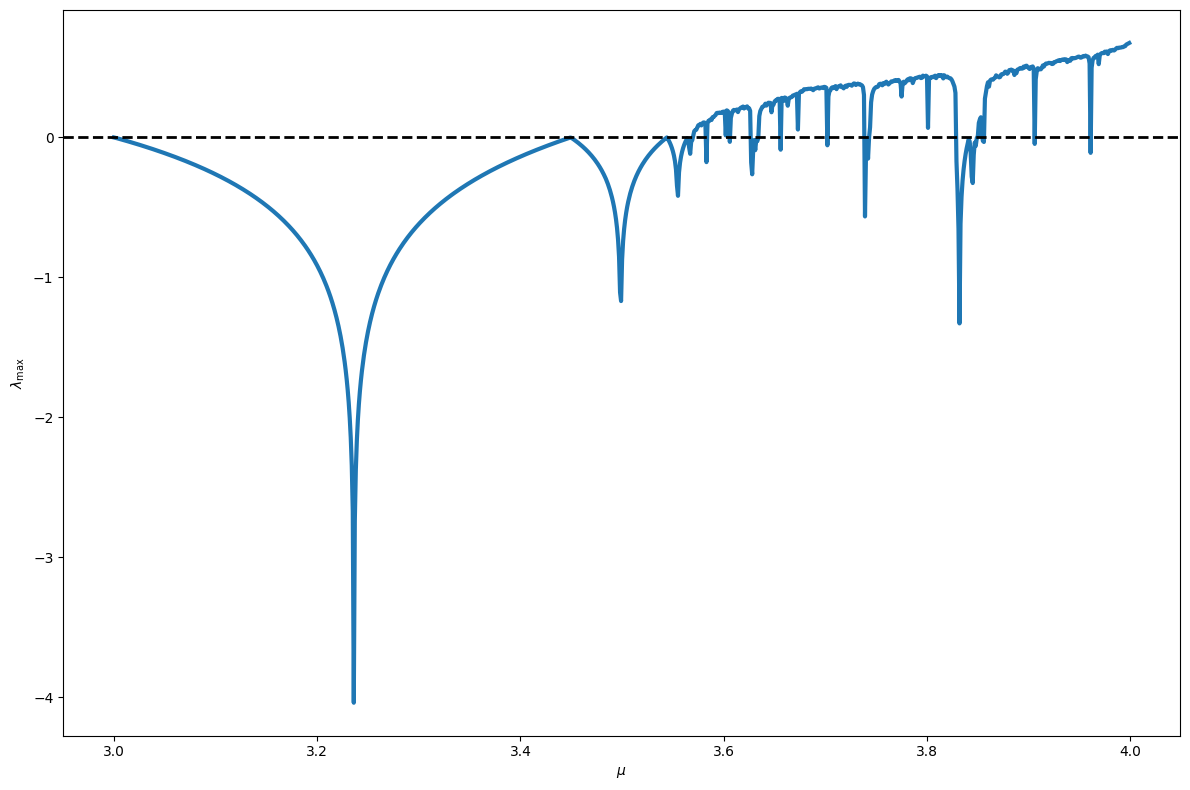

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Logistic map ---
def logistic_map(mu, x):
    return mu * x * (1 - x)

# --- Parameters ---
bif_array = np.arange(3.0, 4.0, 0.001)
lyp_list = []

x0 = 0.3
t_trans = 30
t_lyp = 10**4

# --- Remove transient ---
def remove_trans(mu, x0, t_trans):
    for _ in range(t_trans):
        x0 = logistic_map(mu, x0)
    return x0

# --- Compute Lyapunov exponent ---
for mu in bif_array:
    x_warmup = remove_trans(mu, x0, t_trans)
    x_pert = 1e-6

    lyp = 0.0
    for _ in range(t_lyp):
        ly_local = np.log(np.abs(
            (logistic_map(mu, x_warmup + x_pert) - logistic_map(mu, x_warmup))
            / x_pert
        ))
        lyp += ly_local
        x_warmup = logistic_map(mu, x_warmup)

    lyp_list.append(lyp / t_lyp)

# --- Plot ---
plt.figure(figsize=(12, 8))
plt.plot(bif_array, lyp_list, linewidth=3)

# Horizontal line at y = 0
plt.axhline(0, color='black', linewidth=2, linestyle='--')

plt.xlabel(r'$\mu$')
plt.ylabel(r'$\lambda_{\max}$')

plt.tight_layout()


plt.show()

## FTLE in typical chaos (y-axis in log scale)

Logistic map evolution: 100%|███████| 300000/300000 [00:00<00:00, 484789.01it/s]


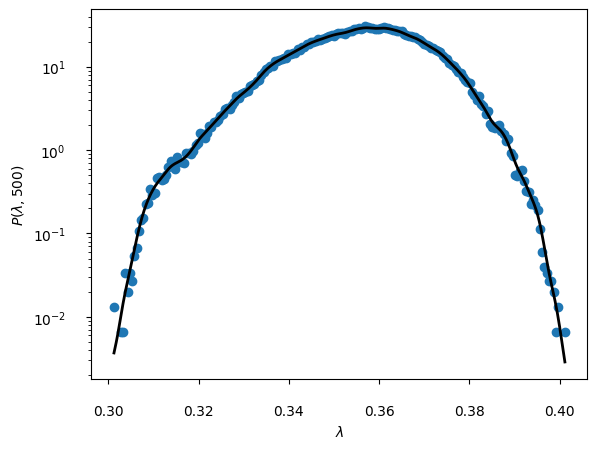

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from tqdm import tqdm


def logistic_map(mu, x):
    return mu * x * (1 - x)

mu = 3.7    

#mu = 4
#mu = 1 + np.sqrt(8) - 1e-6 
#mu = 3.8568007
t_warm = 1000                   # warm-up
long_T = 300000                 # main trajectory length
window_n = 500                  # FTLE window
pert0 = 1e-6                    # initial perturbation size


x = np.random.rand()
for _ in range(t_warm):
    x = logistic_map(mu, x)


delta = pert0

stretch_logs = np.empty(long_T)

for t in tqdm(range(long_T), desc="Logistic map evolution"):

    
    x_next = logistic_map(mu, x)
    x_pert_next = logistic_map(mu, x + delta)

    delta_next = x_pert_next - x_next

    # instantaneous stretch exponent
    stretch_logs[t] = np.log(abs(delta_next) / pert0)
    #delta = pert0 * np.sign(delta_next)

    x = x_next


# Moving window FTLE

ftles = np.convolve(stretch_logs, np.ones(window_n), mode='valid') / window_n
ftles = ftles[:long_T]

# Distribution

counts, bin_edges = np.histogram(ftles, bins=200, density=True)
bin_centers = 0.5*(bin_edges[:-1] + bin_edges[1:])
kde = gaussian_kde(ftles)
xgrid = np.linspace(bin_centers.min(), bin_centers.max(), 600)


#plt.figure(figsize=(12,10))
plt.plot(bin_centers, counts, 'o', markersize=6, label='Histogram points')
plt.plot(xgrid, kde(xgrid), '-', lw=2, label='KDE', color = 'black')

plt.yscale('log')
plt.tick_params(axis='x', pad=15)
plt.tick_params(axis='y', pad=15)

plt.xlabel(r'$\lambda$')
plt.ylabel(r'$ln P(\lambda, 500)$')

plt.show()

## FTLE in fully developed chaos case 

Logistic map evolution: 100%|███████| 300000/300000 [00:00<00:00, 567471.65it/s]


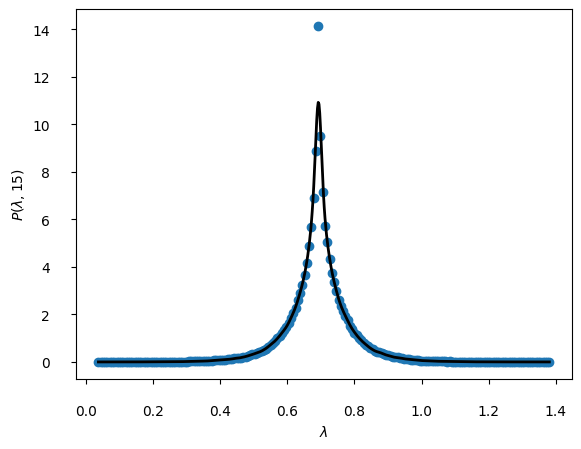

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from tqdm import tqdm


def logistic_map(mu, x):
    return mu * x * (1 - x)

mu = 4    

t_warm = 1000                   # warm-up
long_T = 300000                 # main trajectory length
window_n = 15                  # FTLE window
pert0 = 1e-6                    # initial perturbation size


x = np.random.rand()
for _ in range(t_warm):
    x = logistic_map(mu, x)


delta = pert0

stretch_logs = np.empty(long_T)

for t in tqdm(range(long_T), desc="Logistic map evolution"):

    
    x_next = logistic_map(mu, x)
    x_pert_next = logistic_map(mu, x + delta)

    delta_next = x_pert_next - x_next

    # instantaneous stretch exponent
    stretch_logs[t] = np.log(abs(delta_next) / pert0)
    #delta = pert0 * np.sign(delta_next)

    x = x_next


# Moving window FTLE

ftles = np.convolve(stretch_logs, np.ones(window_n), mode='valid') / window_n
ftles = ftles[:long_T]

# Distribution

counts, bin_edges = np.histogram(ftles, bins=200, density=True)
bin_centers = 0.5*(bin_edges[:-1] + bin_edges[1:])
kde = gaussian_kde(ftles)
xgrid = np.linspace(bin_centers.min(), bin_centers.max(), 600)


#plt.figure(figsize=(12,10))
plt.plot(bin_centers, counts, 'o', markersize=6, label='Histogram points')
plt.plot(xgrid, kde(xgrid), '-', lw=2, label='KDE', color = 'black')

#plt.yscale('log')
plt.tick_params(axis='x', pad=15)
plt.tick_params(axis='y', pad=15)

plt.xlabel(r'$\lambda$')
plt.ylabel(r'$P(\lambda, 15)$')

plt.show()

## FTLE during subduction (intermittency, y-axis in log scale)

Logistic map evolution: 100%|███████| 300000/300000 [00:00<00:00, 436281.48it/s]


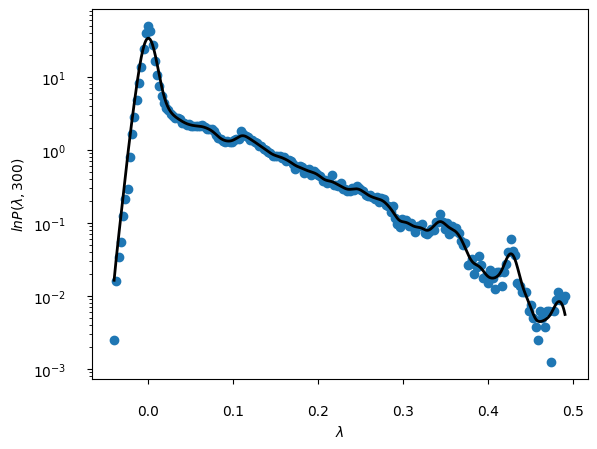

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from tqdm import tqdm


def logistic_map(mu, x):
    return mu * x * (1 - x)


mu = 1 + np.sqrt(8) - 1e-6 

t_warm = 1000                   # warm-up
long_T = 300000                 # main trajectory length
window_n = 300                  # FTLE window
pert0 = 1e-6                    # initial perturbation size


x = np.random.rand()
for _ in range(t_warm):
    x = logistic_map(mu, x)


delta = pert0

stretch_logs = np.empty(long_T)

for t in tqdm(range(long_T), desc="Logistic map evolution"):

    
    x_next = logistic_map(mu, x)
    x_pert_next = logistic_map(mu, x + delta)

    delta_next = x_pert_next - x_next

    # instantaneous stretch exponent
    stretch_logs[t] = np.log(abs(delta_next) / pert0)
    #delta = pert0 * np.sign(delta_next)

    x = x_next


# Moving window FTLE

ftles = np.convolve(stretch_logs, np.ones(window_n), mode='valid') / window_n
ftles = ftles[:long_T]

# Distribution

counts, bin_edges = np.histogram(ftles, bins=200, density=True)
bin_centers = 0.5*(bin_edges[:-1] + bin_edges[1:])
kde = gaussian_kde(ftles)
xgrid = np.linspace(bin_centers.min(), bin_centers.max(), 600)


#plt.figure(figsize=(12,10))
plt.plot(bin_centers, counts, 'o', markersize=6, label='Histogram points')
plt.plot(xgrid, kde(xgrid), '-', lw=2, label='KDE', color = 'black')

plt.yscale('log')
plt.tick_params(axis='x', pad=15)
plt.tick_params(axis='y', pad=15)

plt.xlabel(r'$\lambda$')
plt.ylabel(r'$ln P(\lambda, 300)$')

plt.show()

## FTLE for interior crisis

Logistic map evolution: 100%|███████| 300000/300000 [00:00<00:00, 554491.13it/s]


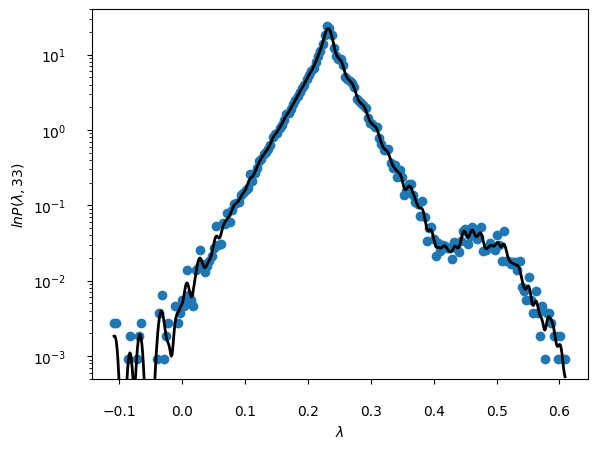

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from tqdm import tqdm


def logistic_map(mu, x):
    return mu * x * (1 - x)

mu = 3.8568007
t_warm = 1000                   # warm-up
long_T = 300000                 # main trajectory length
window_n = 33                  # FTLE window
pert0 = 1e-6                    # initial perturbation size


x = np.random.rand()
for _ in range(t_warm):
    x = logistic_map(mu, x)


delta = pert0

stretch_logs = np.empty(long_T)

for t in tqdm(range(long_T), desc="Logistic map evolution"):

    
    x_next = logistic_map(mu, x)
    x_pert_next = logistic_map(mu, x + delta)

    delta_next = x_pert_next - x_next

    # instantaneous stretch exponent
    stretch_logs[t] = np.log(abs(delta_next) / pert0)
    #delta = pert0 * np.sign(delta_next)

    x = x_next


# Moving window FTLE

ftles = np.convolve(stretch_logs, np.ones(window_n), mode='valid') / window_n
ftles = ftles[:long_T]

# Distribution

counts, bin_edges = np.histogram(ftles, bins=200, density=True)
bin_centers = 0.5*(bin_edges[:-1] + bin_edges[1:])
kde = gaussian_kde(ftles)
xgrid = np.linspace(bin_centers.min(), bin_centers.max(), 600)


#plt.figure(figsize=(12,10))
plt.plot(bin_centers, counts, 'o', markersize=6, label='Histogram points')
plt.plot(xgrid, kde(xgrid), '-', lw=2, label='KDE', color = 'black')

plt.yscale('log')
plt.tick_params(axis='x', pad=15)
plt.tick_params(axis='y', pad=15)
plt.ylim(0.0005, 40)
plt.xlabel(r'$\lambda$')
plt.ylabel(r'$ln P(\lambda, 33)$')

plt.show()